# Lecture 4 — Model Answer
## Scatter & Bubble: Gapminder

---


In [1]:
import pandas as pd
import plotly.express as px
import numpy as np

# Dataset: Gapminder 2007 — GDP, Life Expectancy, Population by Country

df = px.data.gapminder()
print(f"Loaded: {len(df)} rows")
print(df.head())


Loaded: 1704 rows
       country continent  year  lifeExp       pop   gdpPercap iso_alpha  \
0  Afghanistan      Asia  1952   28.801   8425333  779.445314       AFG   
1  Afghanistan      Asia  1957   30.332   9240934  820.853030       AFG   
2  Afghanistan      Asia  1962   31.997  10267083  853.100710       AFG   
3  Afghanistan      Asia  1967   34.020  11537966  836.197138       AFG   
4  Afghanistan      Asia  1972   36.088  13079460  739.981106       AFG   

   iso_num  
0        4  
1        4  
2        4  
3        4  
4        4  


In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1704 entries, 0 to 1703
Data columns (total 8 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   country    1704 non-null   object 
 1   continent  1704 non-null   object 
 2   year       1704 non-null   int64  
 3   lifeExp    1704 non-null   float64
 4   pop        1704 non-null   int64  
 5   gdpPercap  1704 non-null   float64
 6   iso_alpha  1704 non-null   object 
 7   iso_num    1704 non-null   int64  
dtypes: float64(2), int64(3), object(3)
memory usage: 106.6+ KB


In [3]:
df['year'].value_counts()

year
1952    142
1957    142
1962    142
1967    142
1972    142
1977    142
1982    142
1987    142
1992    142
1997    142
2002    142
2007    142
Name: count, dtype: int64

## Task 1 — Model Answer


### Option 1

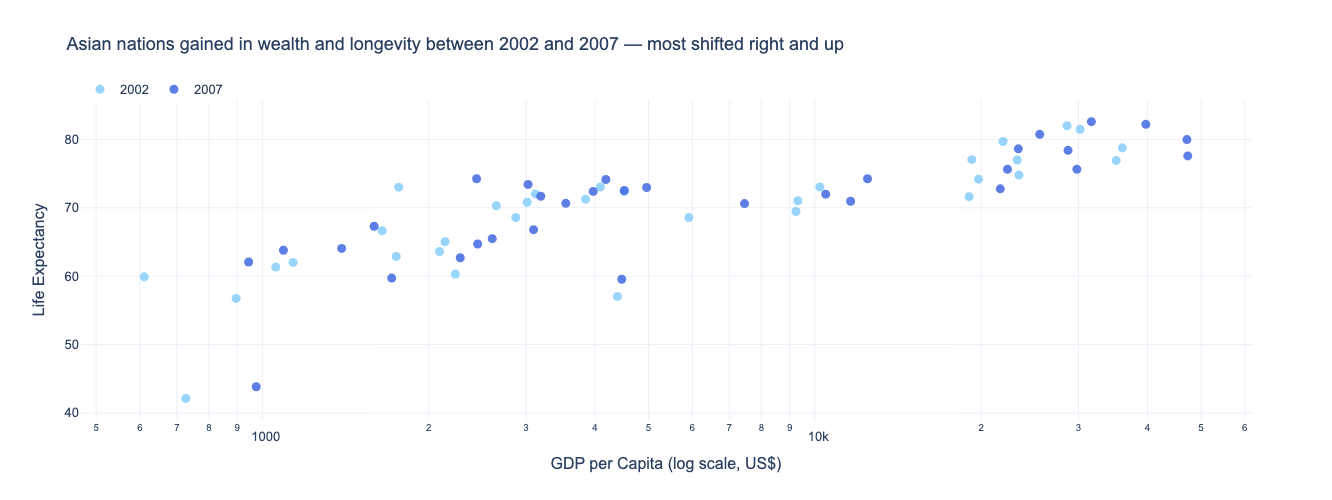

In [7]:
# step 1: prep data

asia = df[(df['continent'] == 'Asia') & (df['year'].isin([2002, 2007]))]
asia.loc[:, 'year'] = asia.loc[:, 'year'].astype(str)

# Step 2: Plotly Express base chart
fig = px.scatter(
    data_frame=asia,
    x='gdpPercap',
    y='lifeExp',
    color='year',                         
    hover_name='country',
    hover_data={'year': False},
    title='Asian nations gained in wealth and longevity between 2002 and 2007 — most shifted right and up',
    labels={'gdpPercap': 'GDP per Capita (log scale, US$)', 'lifeExp': 'Life Expectancy'},
    color_discrete_map={'2002': 'lightskyblue', '2007': 'royalblue'},  
    log_x=True,
    height=500,
    template='plotly_white'
)

# Step 3: additional customisation 
fig.update_traces(
    marker=dict(size=9, opacity=0.85)
)

fig.update_layout(
    font=dict(family='Arial', size=13),
    legend=dict(title='', orientation='h', y=1.08),
)


fig.show()

### Option 2

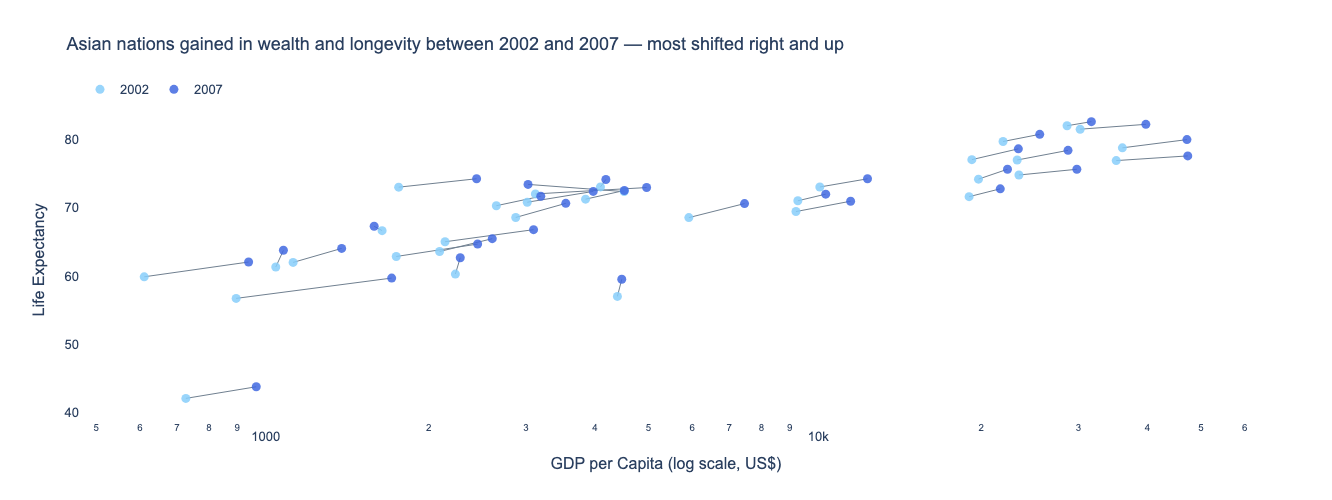

In [18]:
# Step 1: prep data
asia = df[(df['continent'] == 'Asia') & (df['year'].isin([2002, 2007]))].copy()
asia['year'] = asia['year'].astype(str)

# Step 2: Plotly Express base chart
fig = px.scatter(
    data_frame=asia,
    x='gdpPercap',
    y='lifeExp',
    color='year',
    hover_name='country',
    hover_data={'year': False, 'lifeExp': ':.1f', 'gdpPercap': ':,.0f'},
    title='Asian nations gained in wealth and longevity between 2002 and 2007 — most shifted right and up',
    labels={'gdpPercap': 'GDP per Capita (log scale, US$)', 'lifeExp': 'Life Expectancy'},
    color_discrete_map={'2002': 'lightskyblue', '2007': 'royalblue'},
    log_x=True,
    height=500,
    template='plotly_white'
)

# Step 3: connector lines, one per country, drawn behind the points
lines = px.line(asia, x='gdpPercap', y='lifeExp', line_group='country')
lines.update_traces(line=dict(color='slategrey', width=1), hoverinfo='skip')

# add the lines to the fig.data
fig.add_traces(lines.data)  
# traces in fig.data data looks now likes this: (scatter 2002, scatter 2007, line Afghanistan, line Bahrain, ..., line Yemen)

# reorder the fig.data traces 
fig.data = fig.data[2:] + fig.data[:2]   

# Step 4: additional customisation
fig.update_traces(marker=dict(size=9, opacity=0.85), selector=dict(mode='markers'))

fig.update_layout(
    font=dict(family='Arial', size=13),
    legend=dict(title='', orientation='h', y=1.08),
    xaxis=dict(showgrid=False),
    yaxis=dict(showgrid=False)
)

fig.show()

## Task 2 — Model Answer


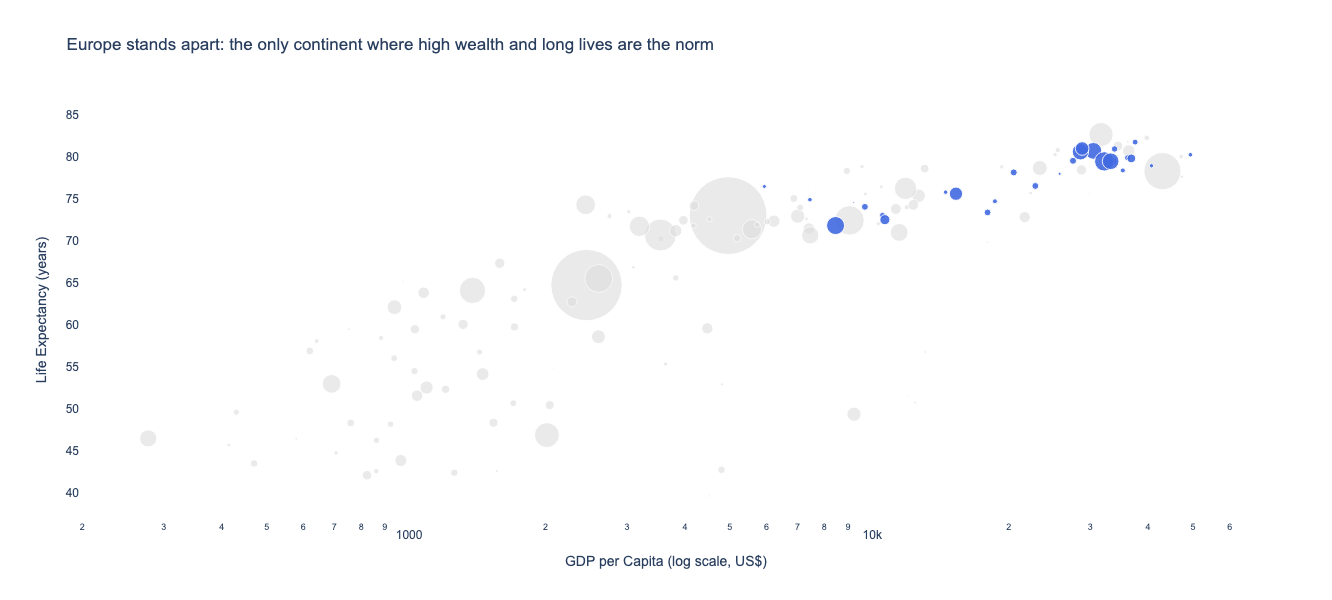

In [26]:

# Step 1: prep data
highlight = 'Europe'
df07 = df.loc[df['year'] == 2007].copy()
df07['color_role'] = df07['continent'].apply(lambda c: 'Europe' if c == highlight else 'Other')


# Step 1: Plotly Express base chart
fig = px.scatter(
    data_frame=df07,
    x='gdpPercap',
    y='lifeExp',
    size='pop',                    # bubble size encodes population
    color='color_role',                    # 'Europe' → blue, 'Other' → grey
    hover_name='country',
    title='Europe stands apart: the only continent where high wealth and long lives are the norm',
    hover_data={'lifeExp': ':.1f', 'gdpPercap': ':,.0f', 'color_role':False, 'pop':':,' },
    labels={'gdpPercap': 'GDP per Capita (log scale, US$)', 'lifeExp': 'Life Expectancy (years)', 'pop': 'Population'},
    color_discrete_map={'Europe': 'royalblue', 'Other': '#DDDDDD'},
    category_orders={'color_role': ['Other', 'Europe']},  # Other drawn first, Europe on top
    log_x=True,
    size_max=55,
    height=600, width=1300,
    template='plotly_white',
    opacity=0.6
    
)

# Step 3: additional customisation

fig.update_traces(
    selector=dict(name='Europe'),
    marker=dict(opacity=0.9))

fig.update_layout(
    showlegend=False,
    font=dict(family='Arial', size=12),
    xaxis=dict(showgrid=False),
    yaxis=dict(showgrid=False))



fig.show()